
# 02 · Manifold — principal-curve trajectory (full malignant manifold)

Bischoff's malignant manifold is **non-branching**: a continuous alveolar
differentiation strip, not a hub radiating to discrete subtypes. The correct
topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on
the joint integrated embedding — **not** a re-embedding (an elongated strip is
honest 1-D geometry; re-embedding an anisotropic strip fabricates folds). Unlike
Kürten the curve is fit on the **whole** manifold (there is no cycling lobe to
exclude). A PPT tree over-fragments this strip into many spurious tips/forks
(noise, not a Puram-style bifurcation), confirming the curve is the right model.
The curve is rooted at the gastrulation/somitogenesis-high tip (developmental
origin), pseudotime flows to the neural-crest terminus, and the embedding is
reoriented to house style (low pseudotime left → high right).
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


### Load processed manifold — keep the full malignant compartment
Cells stay on their *original joint embedding coordinates* — no re-embedding.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('malignant manifold:', sub.shape[0], 'cells on the joint embedding')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP strip aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (elongated -> 1-D geometry)')

malignant manifold: 13382 cells on the joint embedding
UMAP strip aspect ratio (major/minor std): 2.45  (elongated -> 1-D geometry)



### Curve vs tree — confirm non-branching topology
A tree (PPT) is fit first as a control: if the manifold truly bifurcated it would
resolve a small number of clean tips/forks. Instead it over-fragments — evidence the
strip has no real branch. The principal curve then gives a **fold-free** monotone
backbone. A node self-approach ratio > 1 (minimum distance between graph-non-adjacent
nodes, in units of median edge length) certifies the curve does not fold back on
itself; `epg_mu=100` is strong bending regularisation keeping the backbone smooth.

In [4]:
# control: PPT tree over-fragments (no clean bifurcation)
with contextlib.redirect_stdout(io.StringIO()):
    tmp = sub.copy()
    scf.tl.tree(tmp, Nodes=30, use_rep='X_umap', method='ppt', ppt_sigma=1, ppt_lambda=1, seed=SEED, plot=False)
Bt = np.asarray(tmp.uns['graph']['B'])
print(f'PPT tree: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks (over-fragmented -> no clean bifurcation)')
del tmp

PPT tree: 5 tips, 3 forks (over-fragmented -> no clean bifurcation)


In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'principal curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

principal curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)



### Score embryonic modules and derive the root (data-driven)
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest)
are scored against the shared **union** control pool, then graph-smoothed to read
*geography* rather than single-cell dropout. The root is set to the curve tip where
Gast+pSom is highest and Crest lowest — the developmental origin (which, for this
LUAD manifold, is the alveolar/AT2-differentiated pole).

In [6]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 80/81 genes present
pSom: 95/98 genes present
Crest: 103/104 genes present


In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0336 pSom=+0.0613 Crest=-0.0357
tip 2: Gast=-0.0429 pSom=+0.0570 Crest=-0.0304
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.601 p=0.0e+00
  pSom_sm: rho=-0.229 p=2.0e-158
  Crest_sm: rho=+0.290 p=7.1e-258



### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates: pick the axis most aligned with pseudotime as
horizontal, sign it so low pseudotime lands on the left. No rotation/interpolation
(an SVD basis can be a reflection and silently flip an axis). For this manifold the
raw x-axis already tracks pseudotime almost perfectly, so the differentiation strip is
horizontal without a swap. The assertion confirms low pseudotime is on the left.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
cx = np.corrcoef(xy[:,0], t)[0,1]; cy = np.corrcoef(xy[:,1], t)[0,1]
if abs(cx) >= abs(cy):
    xyr = np.column_stack([xy[:,0]*np.sign(cx), xy[:,1]]); conv = f'x horizontal (sign {np.sign(cx):+.0f})'
else:
    xyr = np.column_stack([xy[:,1]*np.sign(cy), -xy[:,0]]); conv = f'swap x<->y (sign {np.sign(cy):+.0f})'
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: {conv}; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: x horizontal (sign +1); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


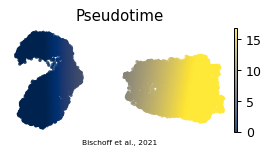

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')